# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

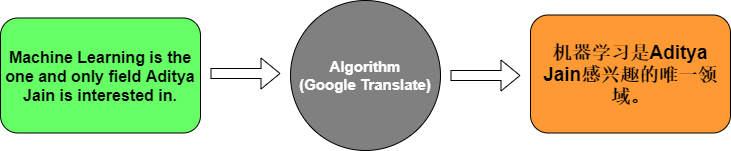

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [3]:
!pip install tensorflow

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 1.8/351.2 MB 6.8 MB/s eta 0:00:52
   ---------------------------------------- 4.2/351.2 MB 8.7 MB/s eta 0:00:40
    --------------------------------------- 6.6/351.2 MB 9.6 MB/s eta 0:00:36
   - -------------------------------------- 8.9/351.2 MB 10.2 MB/s eta 0:00:34
   - -------------------------------------- 11.3/351.2 MB 10.3 MB/s eta 0:00:33
   - -------------------------------------- 13.6/351.2 MB 10.6 MB/s eta 0:00:32
   - -------------------------------------- 15.5/351.2 MB 10.1 MB/s eta 0:00:34
   -- ------------------------------------- 17.8/351.2 MB 10.3 MB/s eta 0:00:33
   -- ------------------------------------- 20.2/351.2 MB 10.4 MB/s eta 0:00:32
   -- ------------------------------------- 22.8/351.2 MB 10.6 MB/s 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.



   ------------------ ---------------------  7/15 [ml_dtypes]
   --------------------- ------------------  8/15 [grpcio]
   --------------------- ------------------  8/15 [grpcio]
   --------------------- ------------------  8/15 [grpcio]
   --------------------- ------------------  8/15 [grpcio]
   ------------------------ ---------------  9/15 [google_pasta]
   ------------------------ ---------------  9/15 [google_pasta]
   -------------------------- ------------- 10/15 [gast]
   -------------------------------- ------- 12/15 [absl-py]
   -------------------------------- ------- 12/15 [absl-py]
   -------------------------------- ------- 12/15 [absl-py]
   ---------------------------------- ----- 13/15 [keras]
   ---------------------------------- ----- 13/15 [keras]
   ---------------------------------- ----- 13/15 [keras]
   ---------------------------------- ----- 13/15 [keras]
   ---------------------------------- ----- 13/15 [keras]
   ---------------------------------- ----- 

In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [5]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [6]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [7]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [8]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.0000e+00 - loss: 2.4879 - val_accuracy: 0.0000e+00 - val_loss: 2.4866
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.2857 - loss: 2.4803 - val_accuracy: 0.0000e+00 - val_loss: 2.4887
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.5714 - loss: 2.4728 - val_accuracy: 0.0000e+00 - val_loss: 2.4909
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.5714 - loss: 2.4649 - val_accuracy: 0.0000e+00 - val_loss: 2.4933
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.5714 - loss: 2.4561 - val_accuracy: 0.0000e+00 - val_loss: 2.4960
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.5714 - loss: 2.4463 - val_accuracy: 0.0000e+00 - val_loss: 2.4989
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.5714 - loss: 2.4350 - val_accuracy: 0.0000e+00 - val_loss: 2.5023
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.5714 - loss: 2.4218 - val

In [9]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 752ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. What does the **Embedding** layer do to a word index?
The Embedding layer converts each word index into a dense numerical vector that represents the word.

2. What is the role of the **Encoder LSTM**?
The Encoder LSTM reads the input sentence and learns its meaning and context.

3. What does the **Decoder LSTM** do?
The Decoder LSTM uses the encoded information to generate the translated sentence word by word.

4. Why do we use `softmax` in the final layer?
Softmax converts the model's outputs into probabilities for each possible word, helping the model select the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

## import Libraries and Load Dataset

In [16]:
import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

df = pd.read_csv("eng_-french.csv")

print(df.head())
print("Dataset shape:", df.shape)

  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !
Dataset shape: (175621, 2)


## Data Preprocessing

In [17]:
# Remove missing values and duplicates
df = df.dropna().drop_duplicates()

# Use 5000 sentence pairs for faster training
df = df.head(5000).copy()

english_sentences = df['English words/sentences'].astype(str).tolist()
french_sentences = df['French words/sentences'].astype(str).tolist()

print("Total sentence pairs:", len(df))
print("English:", english_sentences[0])
print("French:", french_sentences[0])


Total sentence pairs: 5000
English: Hi.
French: Salut!


## Split the Dataset

In [18]:
eng_train_text, eng_test_text, frn_train_text, frn_test_text = train_test_split(
    english_sentences,
    french_sentences,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(eng_train_text))
print("Testing samples:", len(eng_test_text))

Training samples: 4000
Testing samples: 1000


## Tokenization

In [19]:
tokenizer_eng = Tokenizer(oov_token="<OOV>")
tokenizer_frn = Tokenizer(oov_token="<OOV>")

tokenizer_eng.fit_on_texts(eng_train_text)
tokenizer_frn.fit_on_texts(frn_train_text)

eng_train_seq = tokenizer_eng.texts_to_sequences(eng_train_text)
eng_test_seq = tokenizer_eng.texts_to_sequences(eng_test_text)

frn_train_seq = tokenizer_frn.texts_to_sequences(frn_train_text)
frn_test_seq = tokenizer_frn.texts_to_sequences(frn_test_text)

eng_word_index = tokenizer_eng.word_index
frn_word_index = tokenizer_frn.word_index

print("English vocabulary:", len(eng_word_index))
print("French vocabulary:", len(frn_word_index))

English vocabulary: 1152
French vocabulary: 2411


## Padding

In [20]:
max_eng_len = max(map(len, eng_train_seq))
max_frn_len = max(map(len, frn_train_seq))

eng_train = pad_sequences(eng_train_seq, maxlen=max_eng_len)
eng_test = pad_sequences(eng_test_seq, maxlen=max_eng_len)

frn_train = pad_sequences(frn_train_seq, maxlen=max_frn_len)
frn_test = pad_sequences(frn_test_seq, maxlen=max_frn_len)

print("English training shape:", eng_train.shape)
print("French training shape:", frn_train.shape)

English training shape: (4000, 4)
French training shape: (4000, 9)


## Build the LSTM Model

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(max_eng_len,)),
    tf.keras.layers.Embedding(
        input_dim=len(eng_word_index) + 1,
        output_dim=64
    ),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(max_frn_len),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(
            len(frn_word_index) + 1,
            activation='softmax'
        )
    )
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 4, 64)               │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_2 (RepeatVector)       │ (None, 9, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 9, 64)               │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_2 (TimeDistributed) │ (None, 9, 2412)             │         156,780 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 296,620 (1.13 MB)

 Trainable params: 296,620 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

## Train and Evaluate the Model

In [22]:
# Ignore padding positions during training
train_weights = (frn_train != 0).astype("float32")

history = model.fit(
    eng_train,
    frn_train,
    sample_weight=train_weights,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# Evaluate without counting padding positions
test_weights = (frn_test != 0).astype("float32")

loss, accuracy = model.evaluate(
    eng_test,
    frn_test,
    sample_weight=test_weights
)

print("Test Accuracy:", accuracy)


Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.0233 - loss: 2.3146 - val_accuracy: 0.0215 - val_loss: 2.2030
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.0241 - loss: 2.0919 - val_accuracy: 0.0215 - val_loss: 2.2288
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.0241 - loss: 2.0802 - val_accuracy: 0.0215 - val_loss: 2.2518
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.0241 - loss: 2.0761 - val_accuracy: 0.0215 - val_loss: 2.2626
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.0241 - loss: 2.0644 - val_accuracy: 0.0215 - val_loss: 2.2650
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.0263 - loss: 2.2319
Test Accuracy: 0.026333335787057877


## Translate New Sentences

In [23]:

def translate_sentence(sentence):
    sequence = tokenizer_eng.texts_to_sequences([sentence])

    padded = pad_sequences(
        sequence,
        maxlen=max_eng_len
    )

    prediction = model.predict(padded, verbose=0)
    predicted_ids = np.argmax(prediction, axis=-1)

    translation = tokenizer_frn.sequences_to_texts(predicted_ids)

    return translation[0]


# Test translation
sentences = [
    "Hello.",
    "Thank you.",
    "I love you.",
    "Good morning."
]

for sentence in sentences:
    print("English:", sentence)
    print("French:", translate_sentence(sentence))
    print()


English: Hello.
French: je je je je je je je je je

English: Thank you.
French: je je je je je je je je je

English: I love you.
French: je je je je je je je je je

English: Good morning.
French: je je je je je je je je je

